# SAN Assignment - Generalized linear models

Author : Nguyen Thu Uyen Sarah

Email  : nguyet79@fel.cvut.cz

#### Introduction
The aim of this assignment is to practice constructing linear models. You will start with a simple linear model. You will evaluate and interpret it (1p). Consequently, your task will be to improve this model using generalized linear models (GLMs) and feature transformations. You will get 1p for proposal and evaluation of GLM (family, evaluation, interpretation), 1p for correct feature transformations, 2p for proposal and justification of the final model and eventually, 1p for comprehensive evaluation of all the model improvements (ablation study through cross-validation, note that the previous evaluations must be done without cross-validation).

Submit your solution consisting of both this modified notebook file and the exported PDF/HTML document as an archive to the courseware BRUTE upload system for the SAN course.
The deadline is specified there.

#### Input data 
In this assignment, you will work with a student dataset. The dataset contains 200 samples and 4 features: *num_awards* is the outcome variable and indicates the number of awards earned by students in a year, *math* is a continuous predictor variable and represents students’ scores on their math final exam, *prog* is a categorical predictor variable with three levels indicating the type of program in which the students were enrolled (1 = “General”, 2 = “Academic” and 3 = “Vocational”), and *work* is a continuous predictor that gives the number of hours that students spent at work on average per week.

#### Load the necessary libraries and the dataset

In [36]:
library(dplyr)
library(caret) # comprehensive model evaluation
library(splines)
library(ggplot2) # visualizations
library(rcompanion) # comparison of GLMs

d <- read.csv("study_data.csv")

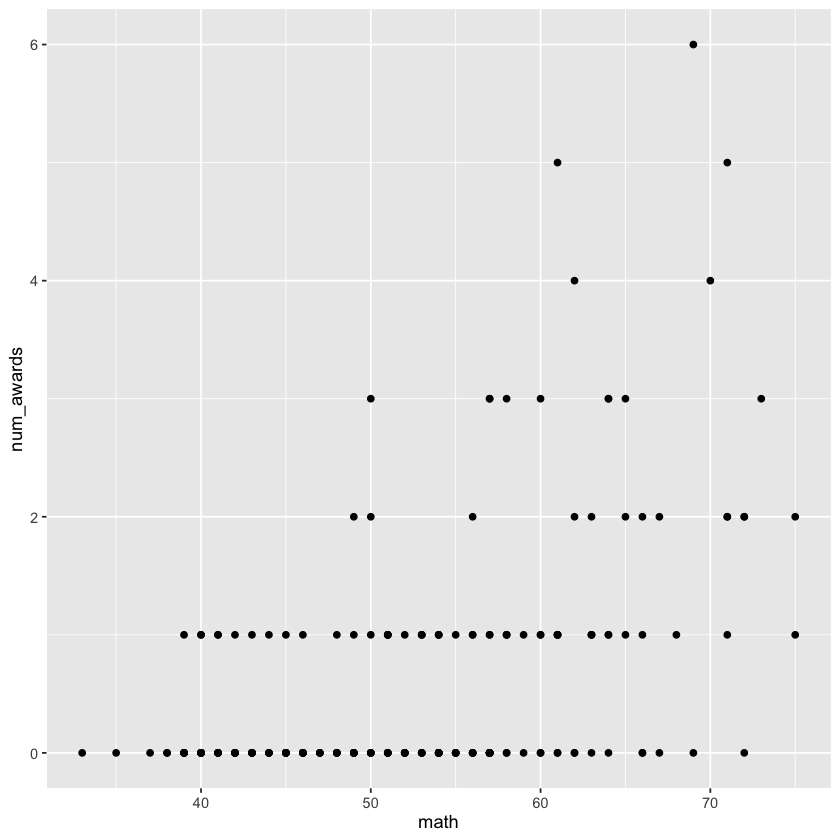

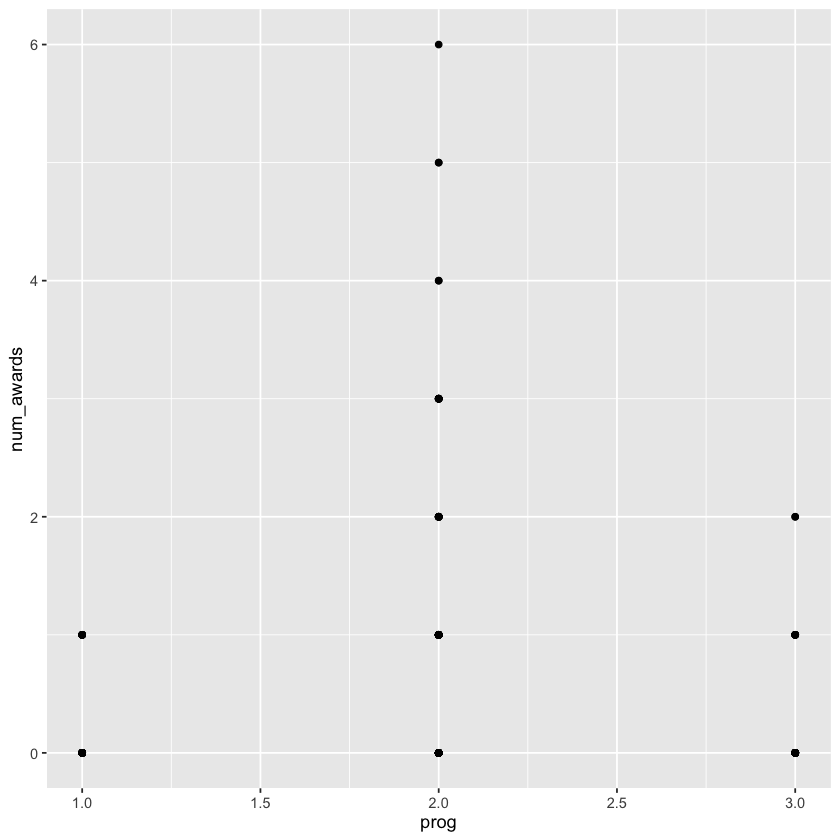

   num_awards        prog            math            work     
 Min.   :0.00   Min.   :1.000   Min.   :33.00   Min.   : 0.0  
 1st Qu.:0.00   1st Qu.:2.000   1st Qu.:45.00   1st Qu.: 4.0  
 Median :0.00   Median :2.000   Median :52.00   Median :19.0  
 Mean   :0.63   Mean   :2.025   Mean   :52.65   Mean   :15.4  
 3rd Qu.:1.00   3rd Qu.:2.250   3rd Qu.:59.00   3rd Qu.:26.0  
 Max.   :6.00   Max.   :3.000   Max.   :75.00   Max.   :35.0  

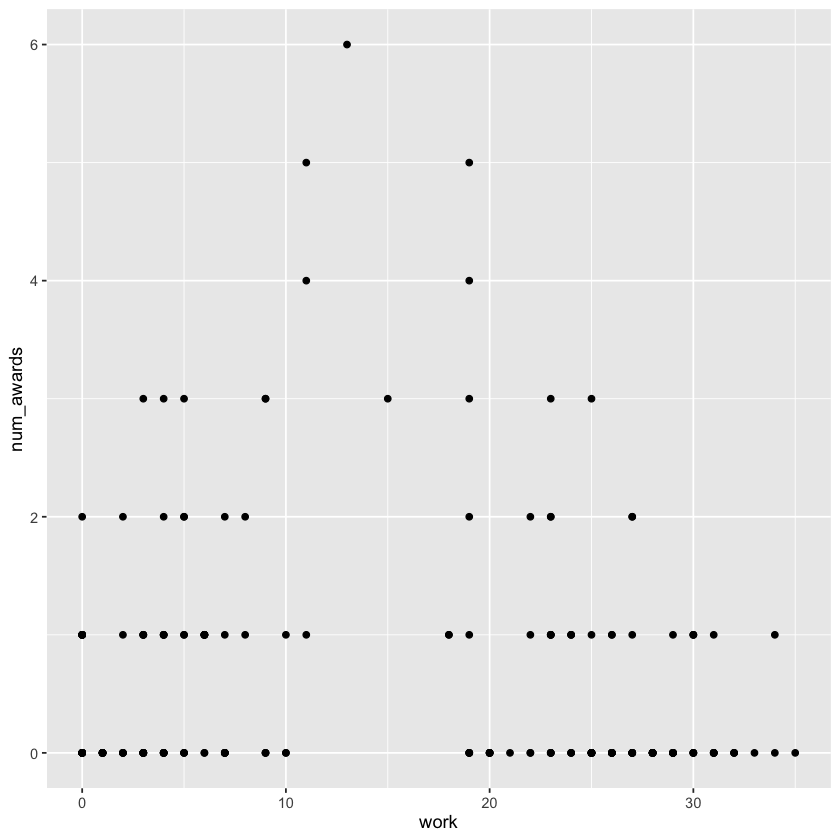

In [37]:
#see what data look like

ggplot(d, aes(x= math, y = num_awards)) + geom_point()
ggplot(d, aes(x= prog, y = num_awards)) + geom_point()
ggplot(d, aes(x= work, y = num_awards)) + geom_point()

summary(d)

In [38]:
set_plot_defaults <- function() {
    par(bg="white",
        col="black",
        col.axis="black",
        col.lab="black",
        col.main="black",
        col.sub="black",
        fg="black")
}

#### Simple linear model
Let us start with an ordinary linear model with no feature transformations. Explain how far the model works (does it meet formal assumptions?, does it overcome the null model?). Which predictors would you keep there and which of them are not useful? Use the standard evaluation procedures that we have for linear models. 



Call:
lm(formula = num_awards ~ ., data = d)

Residuals:
    Min      1Q  Median      3Q     Max 
-1.7526 -0.5680 -0.0862  0.2979  4.4411 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) -2.536344   0.481442  -5.268 3.61e-07 ***
prog         0.109815   0.095972   1.144    0.254    
math         0.056617   0.007130   7.941 1.53e-13 ***
work        -0.002379   0.005807  -0.410    0.682    
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 0.9168 on 196 degrees of freedom
Multiple R-squared:  0.2533,	Adjusted R-squared:  0.2418 
F-statistic: 22.16 on 3 and 196 DF,  p-value: 2.133e-12


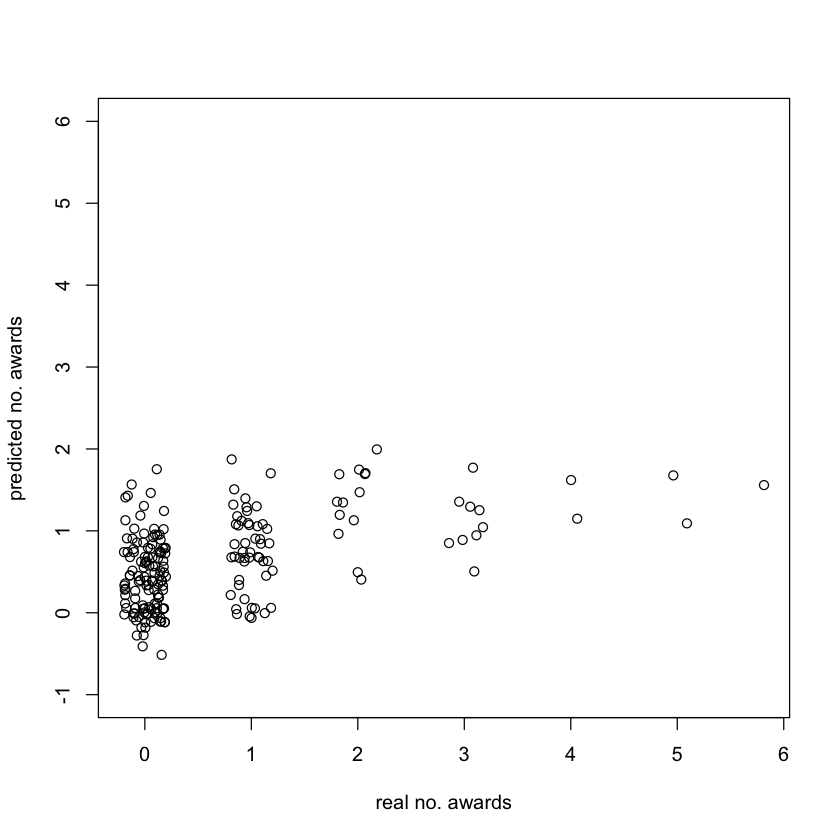

,Df,Sum Sq,Mean Sq,F value,Pr(>F)
,<int>,<dbl>,<dbl>,<dbl>,<dbl>
math,1,54.5093443,54.5093443,64.8496418,7.690496e-14
prog,1,1.2218000,1.2218000,1.4535726,2.294090e-01
work,1,0.1411227,0.1411227,0.1678933,6.824384e-01
Residuals,196,164.7477330,0.8405497,NA,NA


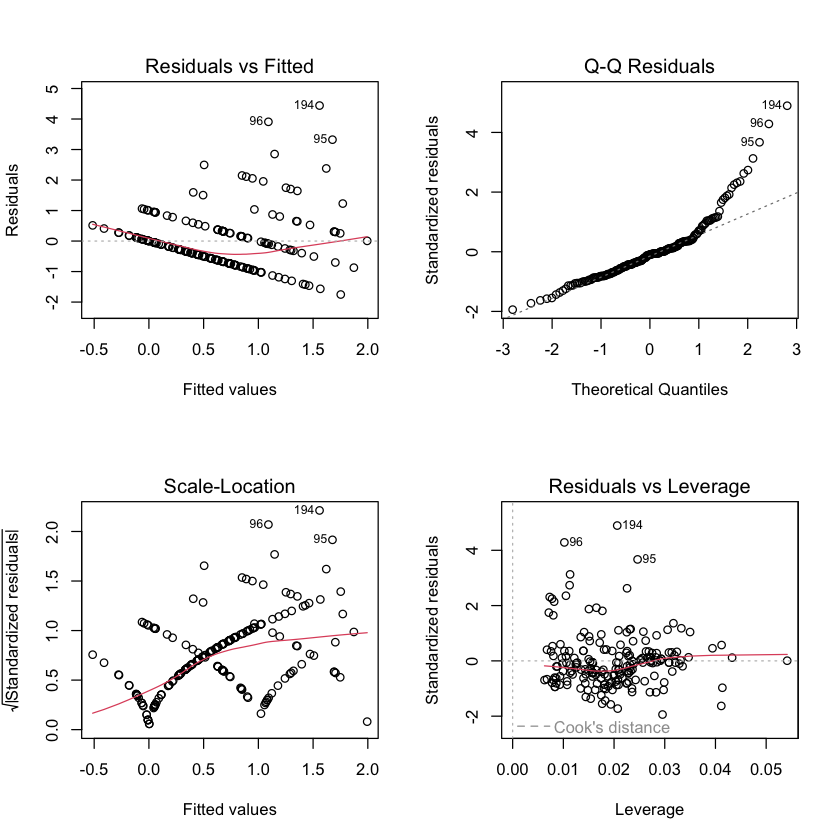

In [39]:
simple_lm <- lm(num_awards ~ ., d)
summary(simple_lm)

set_plot_defaults()

# What are the shortcomings of the simple regression?
plot(d$num_awards+runif(nrow(d),-0.2,0.2),
     predict(simple_lm, d), 
     ylab = 'predicted no. awards',
     xlab = 'real no. awards',
     ylim = c(-1, 6))

par(mfrow=c(2, 2))
plot(simple_lm)

# Refer to the lectures what this call measures
anova(lm(num_awards ~ math + prog + work, d))

## Add your verbal summary here (1p): 

**Does it meet formal assumptions?**
- Assumption of homoscedasticity is violated (Residuals vs fitted plot)
- When we look at Q-Q residuals plot we can see, that the residuals are not normally distributed (Poisson distribution might be better)
Despite this our model is not completely useless (e.g. high p-value), however, these factors might indicate that ols linear reggression is not sufficient. 

**Does it overcome the null model?**
Yes, this is expressed by $R^2$ -> $R^2 = \frac{TSS-RSS}{TSS}$ this ratio expresses the ratio of what is explained by null model and what is explained by linear regression model. 
 
**Summary of linear model**
We see that our model is still quite okay based on the F-statistic and its p-value. In our case p<0.05, which indicates and the model is usable. However, based on the $R^2$ our model only explains 25% of variance in our data, which is quite low.

**Significant variables**
$H_0$ - independent variable doesn't have a statistically significant influence on the dependent variable. 
$H_1$ - Independent variable has a statistically significant influence on the dependent variable. 
The hypotheses can be tested by the two anova runs and their corresponding p-value in lm summary. For variables prog and work we do not have significant p-values -> we fail to reject the null hypothesis in favor of the alternative one. 


##### Generalized linear model
Now, the goal is to implement a generalized linear model that conceptually fits the given task. Do not transform the predictors yet, use them as they are, or omit them from the model. Once you obtain your model, interpret the effect of the *math* predictor on the outcome. How (according to your model) increasing a math score by one point affects the number of awards won? 

Explain why the model overcomes the previous linear model, or justify that the generalized model is not needed. Compare the models theoretically as well as technically in terms of a proper quality measure. Note: The difference between the models cannot be statistically tested.



In [40]:
#### add your code here ####
#rewerite linreg as glm
linreg_glm <- glm(num_awards ~ math, family = "gaussian",  data = d)
summary(linreg_glm)

poisson_reg <- glm(num_awards ~ math , family = "poisson", data = d)
summary(poisson_reg)

compareGLM(linreg_glm, poisson_reg)



Call:
glm(formula = num_awards ~ math, family = "gaussian", data = d)

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) -2.311023   0.370566  -6.236 2.65e-09 ***
math         0.055865   0.006931   8.061 7.06e-14 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for gaussian family taken to be 0.8389427)

    Null deviance: 220.62  on 199  degrees of freedom
Residual deviance: 166.11  on 198  degrees of freedom
AIC: 536.44

Number of Fisher Scoring iterations: 2



Call:
glm(formula = num_awards ~ math, family = "poisson", data = d)

Coefficients:
             Estimate Std. Error z value Pr(>|z|)    
(Intercept) -5.333532   0.591261  -9.021   <2e-16 ***
math         0.086166   0.009679   8.902   <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for poisson family taken to be 1)

    Null deviance: 287.67  on 199  degrees of freedom
Residual deviance: 204.02  on 198  degrees of freedom
AIC: 384.08

Number of Fisher Scoring iterations: 6


$Models
  Formula            
1 "num_awards ~ math"
2 "num_awards ~ math"

$Fit.criteria
  Rank Df.res   AIC  AICc   BIC McFadden Cox.and.Snell Nagelkerke   p.value
1    2    198 536.4 536.6 546.3  0.09666        0.2471     0.2609 7.873e-14
2    2    198 386.1 386.2 396.0  0.18040        0.3418     0.3791 2.986e-20

## Add your verbal summary here (1p): 


We can compare linear regression and glm by formulating linear regression as glm. Afterwards we can take AIC (based on maximum likelihood of seeing our dataset given our model) and we can compare our data with our model. We want our AIC to be as low as possible. 
We can see that the poisson regression outperforms the linear one ($AIC_p = 386.1, AIC_l = 536.4$). 
The best kind of model to fit our data is dependent on what our data look like. In the beginning after visualizing the data we guessed that the data might come from Poisson distribution and that the poisson regression might be better that linear one, which we proved to be true. 

##### Feature transformations and final model
*prog* and *work* did not prove to be effective predictors so far. Visualize these predictors as well as their relationship with the outcome variable. Based on the observations, propose suitable transformations for them (or, justify that they are truly uninformative for prediction of *num_awards*) and implement them into the best model found by now. Use the *compareGLM()* function to validate that your new GLMs indeed improved over the simple one.


typeof(d$prog)

d %>%
  mutate(prog=as.factor(prog)) %>%
  group_by(num_awards, prog) %>%
  summarise(count=n()) %>%
  ggplot(aes(x = num_awards, y=count, fill = prog)) + 
  geom_col(position="dodge") + 
  xlab("Number of awards") + 
  ylab("no. students")

d %>% 
  ggplot(aes(x = work, y = num_awards, color = factor(prog))) + 
  geom_point() + 
  xlab("Work hours") + 
  ylab("Number of awards")

#### add your code here ####

poisson_reg_poly <- glm(num_awards ~ math + poly(work, 2) + poly(prog, 2) , family = "poisson", data = d)
summary(poisson_reg_poly)
poisson_reg_lin <- glm(num_awards ~  work + prog + math, family = "poisson", data = d)
summary(poisson_reg_lin)

poisson_reg_poly1 <- glm(num_awards ~ math + poly(work, 2) , family = "poisson", data = d)
poisson_reg_poly2 <- glm(num_awards ~ math + poly(prog, 2) , family = "poisson", data = d)
compareGLM(poisson_reg_poly1, poisson_reg_poly2, poisson_reg_poly)
compareGLM(poisson_reg_lin, poisson_reg_poly)

## Add your verbal summary here (2p): 

We used polynomial feature transformation for program and work, which seems to decrease AIC even more. The polynomial coefficients came out with significant p-values as well (p< 0.05). This indicates that polynomial feature transformation is better at capturing the relationship between independent variables prog, work and the dependent variable num_awards. We also tried the model with poly(work, 2) + math and poly(prog, 2) + math. This resulted in AIC increasing comparing to poly(work, 2) + poly(prog, 2) + math in our model. This indicates taht both variables provide more information to the model which as a result improves the fit. However, prog is representing labels and not numbers so we cannot treat it as a number (the model will assume linear relationship). We need to convert prog to a categorical variable. However, upon comparison the models turn out to have the same performance despite prog being treated as a number in the first case. 

[1] "integer"

`summarise()` has grouped output by 'num_awards'. You can override using the
`.groups` argument.


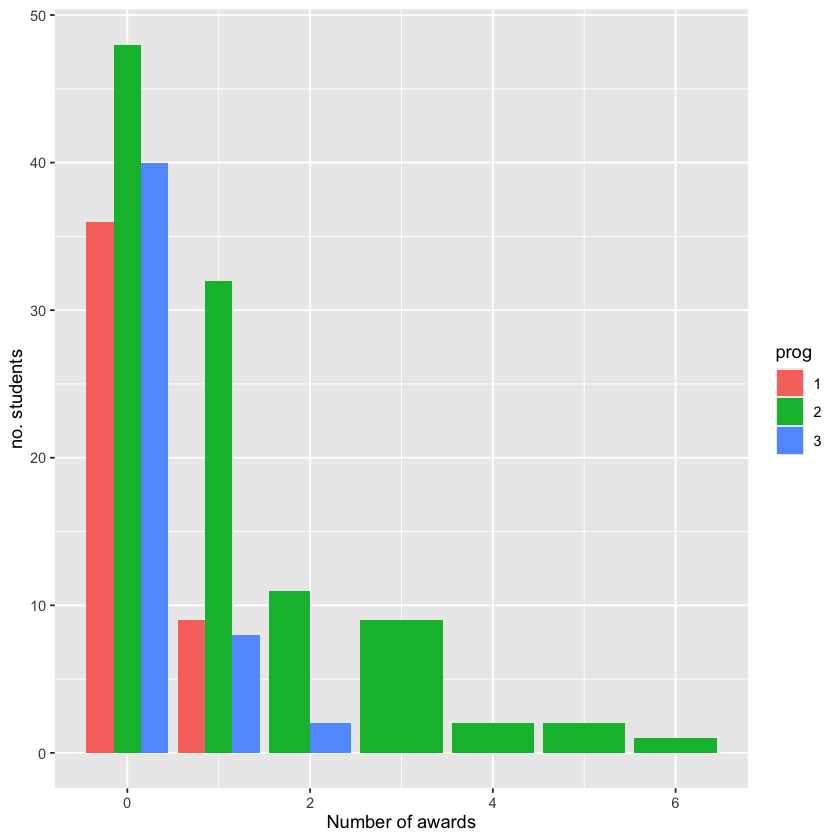


Call:
glm(formula = num_awards ~ math + poly(work, 2) + prog, family = "poisson", 
    data = d)

Coefficients:
               Estimate Std. Error z value Pr(>|z|)    
(Intercept)    -4.58452    0.66683  -6.875 6.20e-12 ***
math            0.05746    0.01093   5.257 1.47e-07 ***
poly(work, 2)1 -2.48088    1.65014  -1.503 0.132726    
poly(work, 2)2 -5.71329    1.57368  -3.631 0.000283 ***
prog2           0.99146    0.35982   2.755 0.005861 ** 
prog3           0.31360    0.44167   0.710 0.477679    
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for poisson family taken to be 1)

    Null deviance: 287.67  on 199  degrees of freedom
Residual deviance: 174.29  on 194  degrees of freedom
AIC: 362.34

Number of Fisher Scoring iterations: 6



Call:
glm(formula = num_awards ~ work + prog + math, family = "poisson", 
    data = d)

Coefficients:
             Estimate Std. Error z value Pr(>|z|)    
(Intercept) -5.090653   0.694492  -7.330 2.30e-13 ***
work        -0.006170   0.008675  -0.711  0.47693    
prog2        1.075059   0.358489   2.999  0.00271 ** 
prog3        0.356662   0.441546   0.808  0.41923    
math         0.069090   0.010741   6.432 1.26e-10 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for poisson family taken to be 1)

    Null deviance: 287.67  on 199  degrees of freedom
Residual deviance: 188.94  on 195  degrees of freedom
AIC: 375

Number of Fisher Scoring iterations: 6


$Models
  Formula                                   
1 "num_awards ~ math + poly(work, 2)"       
2 "num_awards ~ math + prog"                
3 "num_awards ~ math + poly(work, 2) + prog"

$Fit.criteria
  Rank Df.res   AIC  AICc   BIC McFadden Cox.and.Snell Nagelkerke   p.value
1    4    196 372.5 372.8 389.0   0.2184        0.3973     0.4407 4.109e-22
2    4    196 375.5 375.8 392.0   0.2118        0.3881     0.4304 1.855e-21
3    6    194 364.3 364.9 387.4   0.2445        0.4327     0.4800 3.837e-23

$Models
  Formula                                   
1 "num_awards ~ work + prog + math"         
2 "num_awards ~ math + poly(work, 2) + prog"

$Fit.criteria
  Rank Df.res   AIC  AICc   BIC McFadden Cox.and.Snell Nagelkerke   p.value
1    5    195 377.0 377.4 396.8   0.2129        0.3896     0.4321 8.981e-21
2    6    194 364.3 364.9 387.4   0.2445        0.4327     0.4800 3.837e-23

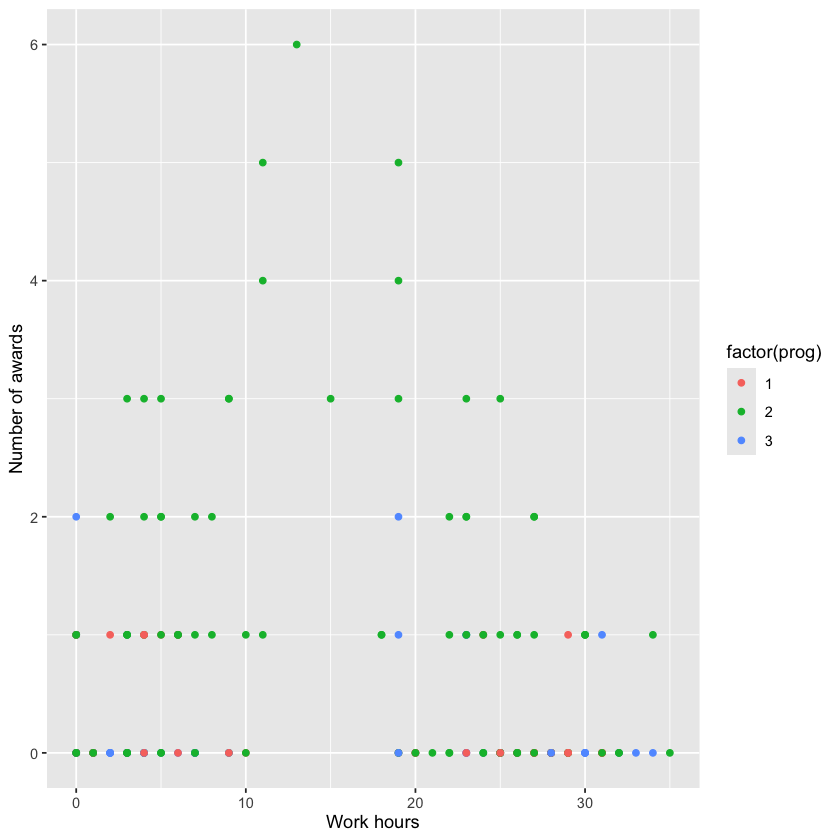

In [41]:
typeof(d$prog)

d %>%
  mutate(prog=as.factor(prog)) %>%
  group_by(num_awards, prog) %>%
  summarise(count=n()) %>%
  ggplot(aes(x = num_awards, y=count, fill = prog)) + 
  geom_col(position="dodge") + 
  xlab("Number of awards") + 
  ylab("no. students")

d %>% 
  ggplot(aes(x = work, y = num_awards, color = factor(prog))) + 
  geom_point() + 
  xlab("Work hours") + 
  ylab("Number of awards")

#### add your code here ####

# Convert prog to factor (categorical variable)
d$prog <- as.factor(d$prog)

# Correct model: polynomial for work, categorical for prog
poisson_reg_poly_cat <- glm(num_awards ~ math + poly(work, 2) + prog, family = "poisson", data = d)
summary(poisson_reg_poly_cat)

# Linear model for comparison
poisson_reg_lin_cat <- glm(num_awards ~ work + prog + math, family = "poisson", data = d)
summary(poisson_reg_lin_cat)

# Individual models
poisson_reg_poly1_cat <- glm(num_awards ~ math + poly(work, 2), family = "poisson", data = d)
poisson_reg_poly2_cat <- glm(num_awards ~ math + prog, family = "poisson", data = d)

compareGLM(poisson_reg_poly1_cat, poisson_reg_poly2_cat, poisson_reg_poly_cat)
compareGLM(poisson_reg_lin_cat, poisson_reg_poly_cat)

##### Ablation study through cross-validation
Recap all the models considered previously and evaluate them through cross-validation. You can start with the most simple null model and gradually add the previously discussed improvements. See their role in terms of MAE, RMSE and other commonly used criteria. The procedure outlined below proposes to work with *train* function from *caret* package, you can only add more models to evaluate and compare.


In [ ]:
library(caret)

d$prog <- as.factor(d$prog)

train_control <- trainControl(method = "cv", number = 10)


# 1. Simple linear model (all predictors)
cv_lm_full <- train(num_awards ~ math + work + prog,
                    data = d,
                    method = "lm",
                    trControl = train_control)

# 2. Linear model with polynomial work
cv_lm_poly <- train(num_awards ~ math + poly(work, 2) + prog,
                    data = d,
                    method = "lm",
                    trControl = train_control)


# 3. Poisson with linear terms
cv_poisson_linear <- train(num_awards ~ math + work + prog,
                           data = d,
                           method = "glm",
                           family = "poisson",
                           trControl = train_control)

# 4. Poisson with polynomial work 
cv_poisson_poly <- train(num_awards ~ math + poly(work, 2) + prog,
                         data = d,
                         method = "glm",
                         family = "poisson",
                         trControl = train_control)



# Create comparison table
results_comparison <- data.frame(
  Model = c("Linear (full)", 
            "Linear (poly)", 
            "Poisson (linear)", 
            "Poisson (poly)"),
  RMSE = c(cv_lm_full$results$RMSE,
           cv_lm_poly$results$RMSE,
           cv_poisson_linear$results$RMSE,
           cv_poisson_poly$results$RMSE),
  Rsquared = c(cv_lm_full$results$Rsquared,
               cv_lm_poly$results$Rsquared,
               cv_poisson_linear$results$Rsquared,
               cv_poisson_poly$results$Rsquared),
  MAE = c(cv_lm_full$results$MAE,
          cv_lm_poly$results$MAE,
          cv_poisson_linear$results$MAE,
          cv_poisson_poly$results$MAE)
)

print(results_comparison)



             Model      RMSE  Rsquared       MAE
1    Linear (full) 0.8865677 0.2747478 0.6386395
2    Linear (poly) 0.8741132 0.3285811 0.6441897
3 Poisson (linear) 0.8814892 0.3721835 0.6103142
4   Poisson (poly) 0.8403887 0.3756601 0.5969112


## Add your verbal summary here (1p): 

Poisson regression model featuring a polynomial work term has the best results. This model achieved the lowest RMSE of 0.840 and MAE of 0.597, while also attaining the highest R-squared value of 0.376, meaning it explains approximately 38% of the variance in the number of awards received. It is also important to choose the type of distribution correctly as we can see that the Poisson outperforms the linear ones. 